# Plot CHIME/FRB Cat2 Data

This notebook loads the publicly available CHIME/FRB data and plots the waterfall with the already determined flags. 

### Import statements

In [1]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import json

### Load data

In [67]:
filename = "FRB20180730A_stokesi_dynamic_spectrum.h5"

with h5py.File(filename, "r") as handler:

    print(handler.attrs.keys())
    
    event_id = handler.attrs["event_id"]
    freq = handler["index_map"]["freqs"][:]
    
    toa = json.loads(handler.attrs["burst_parameters_json"])["arrival_time"]
    time = (handler["index_map"]["times"][:] - np.mean(toa)) * 1e3

    good_freq = handler["good_freq"][:]
    flag = handler["flag"][:]
        
    data = handler["data"][:]
    
    print(handler.attrs["burst_parameters_json"])

<KeysViewHDF5 ['beam_number', 'burst_parameters_json', 'catalog', 'center_time', 'contact', 'creator', 'datatype', 'dm_const', 'dm_incoherent', 'dm_index', 'doi', 'event_id', 'freqs_bin0', 'instrument', 'is_dedispersed', 'num_freq', 'num_time', 'pipeline_parameters_json', 'pulse_emission_region', 'ref_freq', 'repeater_name', 'res_freq', 'res_time', 'start_time_unix_nano', 'stokes', 'telescope', 'times_bin0', 'tns_name', 'unwindowed_num_time', 'unwindowed_times_bin0']>
{"amplitude": [-1.6610962224298984], "arrival_time": [482488.48689058475], "burst_width": [0.0004128824360633611], "dm": [848.8783200451409], "dm_index": [-2.0], "scattering_timescale": [0.01009891957302962], "scattering_index": [-4.0], "spectral_index": [2.078152594885448], "spectral_running": [-7.62940918595922], "ref_freq": [400.1953125]}


### Downsampling in frequency

In [48]:
def bin_freq_channels(data, fbin_factor=4):
    num_chan = data.shape[0]
    if num_chan % fbin_factor != 0:
        raise ValueError("frequency binning factor `fbin_factor` should be even")
    data = np.nanmean(data.reshape((num_chan // fbin_factor, fbin_factor) + data.shape[1:]), axis=1)
    return data


def bin_freq_boolean(arr, fbin_factor=4):
    n = arr.shape[0]
    if n % fbin_factor != 0:
        raise ValueError("frequency binning factor must divide number of channels")

    arr = arr.reshape((n // fbin_factor, fbin_factor) + arr.shape[1:])
    return np.any(arr, axis=1)

binning_factor = 2**4
flag = bin_freq_boolean(flag, fbin_factor=binning_factor)
good_freq = bin_freq_boolean(good_freq, fbin_factor=binning_factor)
data = bin_freq_channels(data, fbin_factor=binning_factor)

### Plotting

Text(0, 0.5, 'Frequency [MHz]')

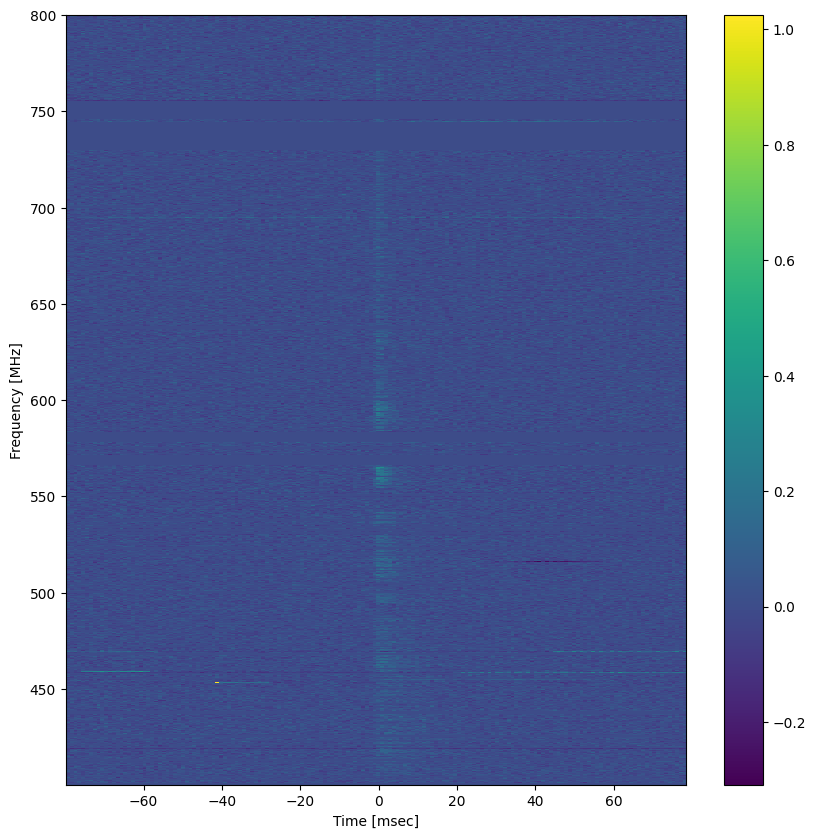

In [49]:
combined_flag = flag & good_freq[:, np.newaxis]
      
fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data * combined_flag,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

In [50]:
len(data)*len(data[0])

165888